# ECG Classification on PTB-XL — Engineered Features vs. Deep Learning

Multi-label classification of 12-lead ECGs into the 5 PTB-XL diagnostic superclasses (NORM, MI, STTC, CD, HYP), comparing two paradigms on identical official splits:

- **Phase A** — signal-processing feature engineering (NeuroKit2) + classical ML (logistic regression, random forest)
- **Phase B** — a 1D CNN trained end-to-end on raw waveforms (PyTorch)
- **Bonus** — a single-lead (lead I) CNN quantifying the information ceiling of smartwatch-style ECG screening

**Headline results (held-out test set, fold 10, macro ROC-AUC):** random forest on 40 engineered features **0.831** → 12-lead CNN **0.924** (literature benchmark ≈ 0.92–0.93) → 1-lead CNN **0.835**.

This project extends my BSc thesis (*"Machine learning techniques for the analysis of cardiac pathologies from electrocardiography data"*, University of Padova) from a literature review to a full implementation, and follows my [tabular heart-disease project](https://github.com/harjoldbrahimaj/heart-disease-prediction) as its natural continuation: from clinical tables to raw signals.

> **Disclaimer**: educational portfolio project. Not a medical device.

**Environment**: Google Colab (T4 GPU for Phase B). Dataset cached on Google Drive.

## 1. Setup and data download

PTB-XL ([PhysioNet](https://physionet.org/content/ptb-xl/1.0.3/)): 21,799 clinical 12-lead ECGs, 10 s each, annotated by cardiologists. We use the 100 Hz version (each record = 1000 samples × 12 leads). The download (~600 MB) is done once and cached on Google Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

data_dir = '/content/drive/MyDrive/ptbxl'
base = 'https://physionet.org/files/ptb-xl/1.0.3'

if not os.path.exists(f'{data_dir}/ptbxl_database.csv'):
    # 100 Hz signals only, preserving the records100/... structure
    !wget -q -r -N -c -np -nH --cut-dirs=3 -P {data_dir} {base}/records100/
    !wget -q -N -P {data_dir} {base}/ptbxl_database.csv
    !wget -q -N -P {data_dir} {base}/scp_statements.csv
    print("Download complete")
else:
    print("Dataset already on Drive")

Dataset already on Drive


In [3]:
import pandas as pd

# One row per ECG: patient info, diagnostic codes, official stratification fold
meta = pd.read_csv(f'{data_dir}/ptbxl_database.csv', index_col='ecg_id')
print(meta.shape)
meta[['age', 'sex', 'scp_codes', 'strat_fold']].head()

(21799, 27)


,age,sex,scp_codes,strat_fold
ecg_id,,,,
1,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",3
2,19.0,0,"{'NORM': 80.0, 'SBRAD': 0.0}",2
3,37.0,1,"{'NORM': 100.0, 'SR': 0.0}",5
4,24.0,0,"{'NORM': 100.0, 'SR': 0.0}",3
5,19.0,1,"{'NORM': 100.0, 'SR': 0.0}",4


## 2. Labels: from 71 SCP codes to 5 diagnostic superclasses

Each ECG carries a dictionary of SCP-ECG statements with cardiologist likelihoods (e.g. `{'IMI': 35.0, 'SR': 0.0}`). Using the official `scp_statements.csv` mapping, diagnostic codes are aggregated into 5 superclasses: **NORM, MI, STTC, CD, HYP**; non-diagnostic codes (rhythm/form statements like SR) are filtered out.

Key property of the task: it is **multi-label** — one ECG can carry several diagnoses simultaneously. This is not a corner case: ~5,100 ECGs (24%) have 2+ superclasses. The target is therefore a binary *matrix* (one column per superclass), and the model answers five independent yes/no questions.

In [4]:
import ast
from collections import Counter

# scp_codes is stored as a string -> convert to real dicts
meta['scp_codes'] = meta['scp_codes'].apply(ast.literal_eval)

scp_map = pd.read_csv(f'{data_dir}/scp_statements.csv', index_col=0)
scp_map = scp_map[scp_map['diagnostic'] == 1]

def to_superclasses(codes: dict):
    """From {code: likelihood} to the sorted list of diagnostic superclasses."""
    classes = set()
    for code in codes:
        if code in scp_map.index:
            classes.add(scp_map.loc[code, 'diagnostic_class'])
    return sorted(classes)

meta['superclasses'] = meta['scp_codes'].apply(to_superclasses)

print(Counter(c for lst in meta['superclasses'] for c in lst))
print(meta['superclasses'].apply(len).value_counts().sort_index())

Counter({'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'CD': 4898, 'HYP': 2649})
superclasses
0      411
1    16244
2     4068
3      919
4      157
Name: count, dtype: int64


Counts match the official PTB-XL paper (NORM 9514, MI 5469, STTC 5235, CD 4898, HYP 2649) — a good sanity check of the decoding. Note the class imbalance: HYP is 3.6× rarer than NORM. 411 ECGs carry no diagnostic superclass and are excluded (undefined target for this task).

In [5]:
from sklearn.preprocessing import MultiLabelBinarizer

meta_lab = meta[meta['superclasses'].apply(len) > 0].copy()

mlb = MultiLabelBinarizer()
Y = pd.DataFrame(mlb.fit_transform(meta_lab['superclasses']),
                 index=meta_lab.index, columns=mlb.classes_)
print(Y.shape)
Y.head()

(21388, 5)


,CD,HYP,MI,NORM,STTC
ecg_id,,,,,
1,0,0,0,1,0
2,0,0,0,1,0
3,0,0,0,1,0
4,0,0,0,1,0
5,0,0,0,1,0


## 3. A first look at the raw signals

Signals are read with `wfdb` (the standard PhysioNet reader). Comparing a normal ECG with an inferior MI (ecg_id 8): the MI signs live in the *beat morphology* of the inferior leads (II, III, aVF) — pathological Q waves and ST/T changes — while the large slow oscillation visible in some leads is **baseline wander** (respiration/movement artifact, ~0.2–0.5 Hz), i.e. noise, not pathology. Distinguishing the two matters: a model could otherwise learn noise correlates instead of disease.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 24.8 MB/s eta 0:00:00


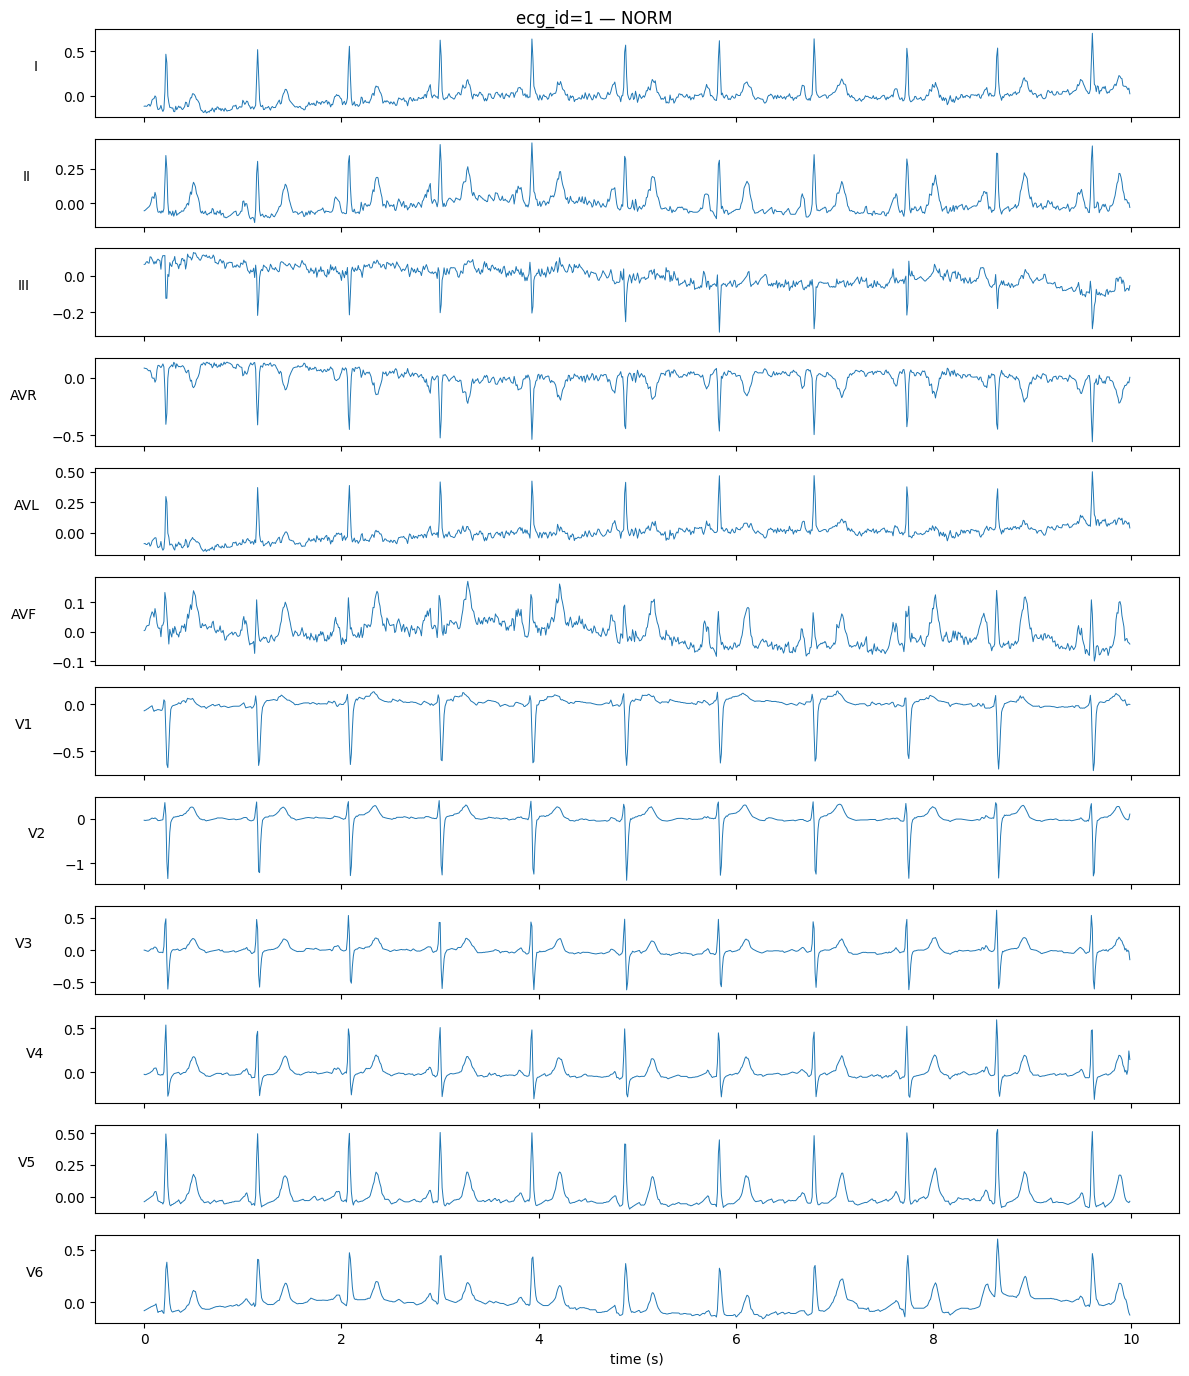

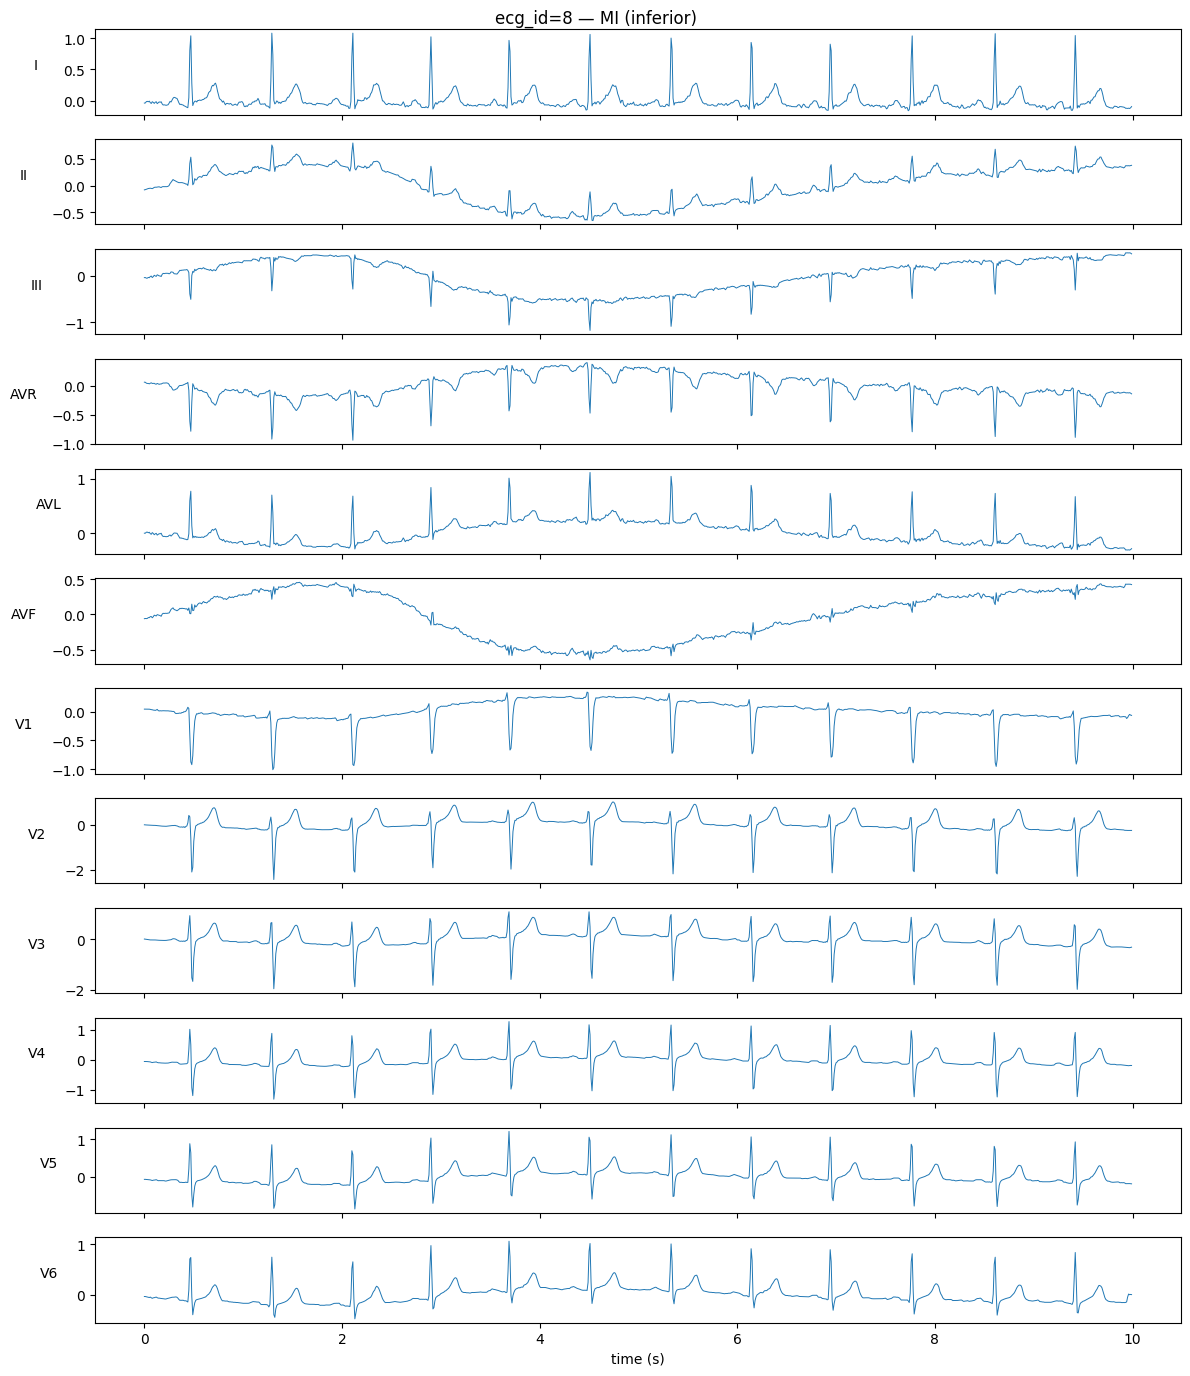

In [6]:
!pip install wfdb neurokit2 -q
import wfdb
import numpy as np
import matplotlib.pyplot as plt

def load_ecg(ecg_id):
    """Return (1000 x 12) signal for one ECG."""
    path = f"{data_dir}/{meta_lab.loc[ecg_id, 'filename_lr']}"
    signal, fields = wfdb.rdsamp(path)
    return signal, fields

for ecg_id, title in [(1, 'NORM'), (8, 'MI (inferior)')]:
    signal, fields = load_ecg(ecg_id)
    fig, axes = plt.subplots(12, 1, figsize=(12, 14), sharex=True)
    t = np.arange(signal.shape[0]) / 100
    for i, ax in enumerate(axes):
        ax.plot(t, signal[:, i], linewidth=0.7)
        ax.set_ylabel(fields['sig_name'][i], rotation=0, labelpad=20)
    axes[-1].set_xlabel('time (s)')
    fig.suptitle(f'ecg_id={ecg_id} — {title}')
    plt.tight_layout(); plt.show()

## 4. Signal preprocessing and R-peak detection

NeuroKit2's `ecg_clean` (band-pass filtering) removes baseline wander and high-frequency noise; `ecg_peaks` locates R peaks — the anchor for rhythm features. Demonstrated on lead II of the MI record:

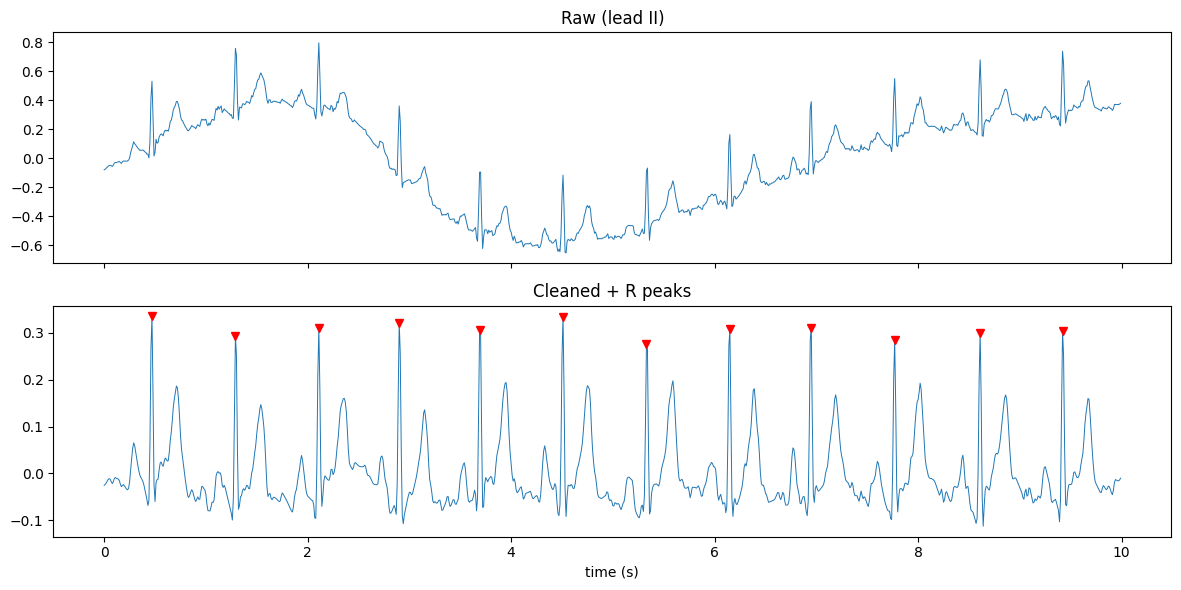

Mean HR: 74 bpm, RR std: 14 ms


In [7]:
import neurokit2 as nk

signal, fields = load_ecg(8)
lead_II = signal[:, 1]

clean = nk.ecg_clean(lead_II, sampling_rate=100)
peaks, info = nk.ecg_peaks(clean, sampling_rate=100)
r_locs = info['ECG_R_Peaks']

t = np.arange(len(lead_II)) / 100
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, lead_II, linewidth=0.7);  axes[0].set_title('Raw (lead II)')
axes[1].plot(t, clean, linewidth=0.7);    axes[1].set_title('Cleaned + R peaks')
axes[1].plot(r_locs / 100, clean[r_locs], 'rv')
plt.xlabel('time (s)'); plt.tight_layout(); plt.show()

rr = np.diff(r_locs) / 100
print(f"Mean HR: {60 / rr.mean():.0f} bpm, RR std: {rr.std()*1000:.0f} ms")

## 5. Phase A — feature engineering at scale

For every ECG, a deliberately simple v1 feature vector (40 features, three families):

1. **Rhythm** (lead II): mean HR, RR std/min/max
2. **Amplitudes**: median R-peak amplitude per lead
3. **Coarse morphology/energy**: per-lead std and peak-to-peak range

Robustness rules for 21k real-world signals: a `try/except` so one corrupt record cannot kill the loop, but with explicit *counting* of discards — silent failures concentrated in one class would introduce bias. Result: 21,353/21,388 extracted (0.16% discarded, scattered). The loop was timed on 100 records before the full run (~18 min), and the output is cached as CSV on Drive.

In [8]:
from time import time
from tqdm.notebook import tqdm

def extract_features(ecg_id):
    """Feature dict for one ECG; None if the signal is unusable."""
    try:
        signal, _ = load_ecg(ecg_id)
        feats = {'ecg_id': ecg_id}
        clean_II = nk.ecg_clean(signal[:, 1], sampling_rate=100)
        _, info = nk.ecg_peaks(clean_II, sampling_rate=100)
        r = info['ECG_R_Peaks']
        if len(r) < 3:
            return None
        rr = np.diff(r) / 100
        feats['hr_mean'] = 60 / rr.mean()
        feats['rr_std'], feats['rr_min'], feats['rr_max'] = rr.std(), rr.min(), rr.max()
        for i in range(12):
            lead = nk.ecg_clean(signal[:, i], sampling_rate=100)
            feats[f'r_amp_{i}'] = np.median(lead[r])
            feats[f'std_{i}']   = lead.std()
            feats[f'ptp_{i}']   = np.ptp(lead)
        return feats
    except Exception:
        return None

feat_path = f'{data_dir}/features_v1.csv'
if not os.path.exists(feat_path):
    rows = [f for f in (extract_features(i) for i in tqdm(meta_lab.index)) if f]
    features = pd.DataFrame(rows).set_index('ecg_id')
    features.to_csv(feat_path)
else:
    features = pd.read_csv(feat_path, index_col='ecg_id')
print(features.shape)

(21353, 40)


## 6. Phase A — classical models on the official splits

PTB-XL ships 10 patient-stratified folds: **folds 1–8 = training, fold 9 = validation, fold 10 = test** (locked until the final comparison). Two reasons to use them instead of a custom split: (1) the same patient may have multiple ECGs — a random split would leak patient identity between train and test (*patient-level leakage*: the model recognizes the patient, not the disease); (2) results become directly comparable with published benchmarks.

Multi-label handling: `OneVsRestClassifier` trains 5 independent logistic regressions; the random forest handles multi-label natively. Metric: per-class ROC-AUC + macro average (the PTB-XL standard).

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

common = features.index.intersection(Y.index)
X_feat, Y_lab = features.loc[common], Y.loc[common]
folds = meta_lab.loc[common, 'strat_fold']

X_tr, Y_tr = X_feat[folds <= 8], Y_lab[folds <= 8]
X_va, Y_va = X_feat[folds == 9], Y_lab[folds == 9]
X_te, Y_te = X_feat[folds == 10], Y_lab[folds == 10]   # VAULT: opened once, at the end
print(f"train {len(X_tr)}, val {len(X_va)}, test {len(X_te)}")

model_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42)))
])
model_lr.fit(X_tr, Y_tr)
auc_lr = roc_auc_score(Y_va, model_lr.predict_proba(X_va), average=None)
for c, a in zip(Y_lab.columns, auc_lr):
    print(f"  {c}: {a:.3f}")
print(f"  LogReg macro-AUC: {auc_lr.mean():.3f}")

train 17058, val 2139, test 2156
  CD: 0.827
  HYP: 0.830
  MI: 0.801
  NORM: 0.840
  STTC: 0.781
  LogReg macro-AUC: 0.816


In [10]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_tr, Y_tr)

proba_rf = np.column_stack([p[:, 1] for p in rf.predict_proba(X_va)])
auc_rf = roc_auc_score(Y_va, proba_rf, average=None)
for c, a in zip(Y_lab.columns, auc_rf):
    print(f"  {c}: {a:.3f}")
print(f"  RF macro-AUC: {auc_rf.mean():.3f}")

  CD: 0.844
  HYP: 0.887
  MI: 0.845
  NORM: 0.871
  STTC: 0.771
  RF macro-AUC: 0.844


**Validation results**: LogReg 0.816, **RF 0.844** — this time (unlike the tabular UCI project) the more complex model wins clearly: with 17k training examples there is enough data to exploit non-linear interactions. Same selection rule, opposite outcome — the dataset decides, not ideology.

The per-class pattern tells the real story: **HYP is the best class (0.887)** because hypertrophy is diagnosed via *voltage criteria* that our amplitude features capture directly; **STTC (0.771) and MI (0.845) underperform** because they live in fine morphology (ST segment, Q waves, T waves) that 40 coarse features cannot see. That gap is precisely what a CNN should close.

## 7. Phase B — 1D CNN on raw waveforms

Setup: T4 GPU runtime; all signals cached once as a single ~1 GB `.npy` on Drive (loading 21k individual files from Drive each session is prohibitive).

Concept: a first-layer 1D convolution filter is a learned ~70 ms template that activates on morphological primitives (steep slopes, narrow peaks, small negative deflections). Stacked blocks with pooling widen the effective receptive field: waves → whole P-QRS-T complexes → rhythm. The features engineered by hand in Phase A here *emerge* from the data.

In [11]:
sig_path = f'{data_dir}/signals_100hz.npy'
ids_path = f'{data_dir}/signals_ids.npy'

if not os.path.exists(sig_path):
    ids = common.to_numpy()
    X_sig = np.zeros((len(ids), 1000, 12), dtype=np.float32)
    for k, ecg_id in enumerate(tqdm(ids)):
        X_sig[k], _ = load_ecg(ecg_id)
    np.save(sig_path, X_sig); np.save(ids_path, ids)
else:
    X_sig = np.load(sig_path); ids = np.load(ids_path)
print(X_sig.shape, X_sig.dtype)

(21353, 1000, 12) float32


In [12]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

Y_sig = Y.loc[ids].to_numpy(np.float32)
folds_sig = meta_lab.loc[ids, 'strat_fold'].to_numpy()
tr, va, te = folds_sig <= 8, folds_sig == 9, folds_sig == 10

# Per-lead standardization with TRAINING statistics only (no leakage)
mu = X_sig[tr].mean(axis=(0, 1), keepdims=True)
sd = X_sig[tr].std(axis=(0, 1), keepdims=True)
Xn = (X_sig - mu) / sd

def make_loader(mask, shuffle):
    ds = TensorDataset(torch.from_numpy(Xn[mask].transpose(0, 2, 1)),  # (N,12,1000)
                       torch.from_numpy(Y_sig[mask]))
    return DataLoader(ds, batch_size=128, shuffle=shuffle)

dl_tr, dl_va, dl_te = make_loader(tr, True), make_loader(va, False), make_loader(te, False)

cuda


In [13]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv1d(c_in, c_out, kernel_size=7, padding=3),
        nn.BatchNorm1d(c_out),
        nn.ReLU(),
        nn.MaxPool1d(2),   # halves resolution -> doubles effective receptive field
    )

model = nn.Sequential(
    conv_block(12, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, 5),
).to(device)

loss_fn = nn.BCEWithLogitsLoss()   # 5 independent binary problems = multi-label in one line
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
print(sum(p.numel() for p in model.parameters()), "parameters")

190757 parameters


> **Note on this saved copy.** The training loop below was run once on a Colab T4 (its log is summarized right after it). It is intentionally *not* re-executed here: re-running it would overwrite `cnn_best.pt`, and GPU non-determinism would shift the last decimals of the results. Section 8 reloads that checkpoint and reproduces every reported number.

In [ ]:
def eval_auc(dl):
    model.eval()
    ps, ys = [], []
    with torch.no_grad():
        for xb, yb in dl:
            ps.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
            ys.append(yb.numpy())
    return roc_auc_score(np.vstack(ys), np.vstack(ps), average=None)

best_auc = 0
for epoch in range(15):
    model.train()
    tot = 0
    for xb, yb in dl_tr:
        opt.zero_grad()
        loss = loss_fn(model(xb.to(device)), yb.to(device))
        loss.backward()
        opt.step()
        tot += loss.item() * len(xb)
    auc_va = eval_auc(dl_va)
    print(f"epoch {epoch+1:2d} | loss {tot/tr.sum():.4f} | val macro-AUC {auc_va.mean():.3f}")
    if auc_va.mean() > best_auc:
        best_auc = auc_va.mean()
        torch.save(model.state_dict(), f'{data_dir}/cnn_best.pt')
print(f"Best val macro-AUC: {best_auc:.3f}")

**Training reading** (observed run): loss decreases monotonically; validation macro-AUC climbs fast (0.906 → 0.927 in 5 epochs), plateaus, peaks at **0.929** (epoch 12), then *declines* (0.919 at epoch 15) while the loss keeps dropping — **overfitting onset, live**. Keeping the best-on-validation checkpoint is what protects the final model.

**Reproduce from the saved checkpoint.** Evaluation helper used by section 8 (runs on CPU, no retraining needed).

In [14]:
# Evaluation helper - needed when the training cell above is skipped
def eval_auc(dl):
    model.eval()
    ps, ys = [], []
    with torch.no_grad():
        for xb, yb in dl:
            ps.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
            ys.append(yb.numpy())
    return roc_auc_score(np.vstack(ys), np.vstack(ps), average=None)

## 8. The verdict — both paradigms on the held-out test set (fold 10)

In [15]:
model.load_state_dict(torch.load(f'{data_dir}/cnn_best.pt'))
auc_cnn = eval_auc(dl_te)

proba_rf_te = np.column_stack([p[:, 1] for p in rf.predict_proba(X_te)])
auc_rf_te = roc_auc_score(Y_te, proba_rf_te, average=None)

print(f"{'class':6s} {'RF-feat':>8s} {'CNN':>8s} {'gap':>7s}")
for c, a_rf, a_cnn in zip(Y_lab.columns, auc_rf_te, auc_cnn):
    print(f"{c:6s} {a_rf:8.3f} {a_cnn:8.3f} {a_cnn-a_rf:+7.3f}")
print(f"{'macro':6s} {auc_rf_te.mean():8.3f} {auc_cnn.mean():8.3f} {auc_cnn.mean()-auc_rf_te.mean():+7.3f}")

class   RF-feat      CNN     gap
CD        0.828    0.920  +0.092
HYP       0.862    0.899  +0.037
MI        0.831    0.925  +0.094
NORM      0.858    0.943  +0.085
STTC      0.775    0.934  +0.159
macro     0.831    0.924  +0.093


**Test results** (observed):

| class | RF-features | CNN 12-lead | gap |
|---|---|---|---|
| CD | 0.828 | 0.920 | +0.092 |
| HYP | 0.862 | 0.899 | **+0.037** |
| MI | 0.831 | 0.925 | +0.094 |
| NORM | 0.858 | 0.943 | +0.085 |
| STTC | 0.775 | 0.934 | **+0.159** |
| **macro** | **0.831** | **0.924** | **+0.093** |

The pre-registered hypothesis is confirmed: the largest gap is on **STTC** (fine ST/T morphology, invisible to coarse features), the smallest on **HYP** (voltage criteria already captured by amplitude features). Test AUC (0.924) matches validation (0.929) — the model generalizes — and sits in the published benchmark range (≈0.92–0.93). **Deep learning pays exactly where hand-coded knowledge stops.**

## 9. Smartwatch experiment — how much diagnosis fits in one lead?

A smartwatch records approximately lead I (arm-to-arm). Same architecture, same training, input restricted to that single channel — a clean ablation of the acquisition hardware.

> As above: the single-lead training loop was run once and is not re-executed in this copy. The cell after it reloads `cnn_1lead_best.pt` and reproduces the results.

In [ ]:
def make_loader_1lead(mask, shuffle):
    ds = TensorDataset(torch.from_numpy(Xn[mask][:, :, 0:1].transpose(0, 2, 1)),
                       torch.from_numpy(Y_sig[mask]))
    return DataLoader(ds, batch_size=128, shuffle=shuffle)

dl_tr1, dl_va1, dl_te1 = (make_loader_1lead(m, s) for m, s in [(tr, True), (va, False), (te, False)])

model = nn.Sequential(
    conv_block(1, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, 5),
).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

best_auc = 0
for epoch in range(15):
    model.train()
    for xb, yb in dl_tr1:
        opt.zero_grad()
        loss_fn(model(xb.to(device)), yb.to(device)).backward()
        opt.step()
    auc_va = eval_auc(dl_va1)
    print(f"epoch {epoch+1:2d} | val macro-AUC {auc_va.mean():.3f}")
    if auc_va.mean() > best_auc:
        best_auc = auc_va.mean()
        torch.save(model.state_dict(), f'{data_dir}/cnn_1lead_best.pt')

model.load_state_dict(torch.load(f'{data_dir}/cnn_1lead_best.pt'))
auc_1l = eval_auc(dl_te1)
print(f"\n{'class':6s} {'12-lead':>8s} {'1-lead':>8s} {'loss':>8s}")
for c, a12, a1 in zip(Y_lab.columns, auc_cnn, auc_1l):
    print(f"{c:6s} {a12:8.3f} {a1:8.3f} {a1-a12:+8.3f}")
print(f"{'macro':6s} {auc_cnn.mean():8.3f} {auc_1l.mean():8.3f} {auc_1l.mean()-auc_cnn.mean():+8.3f}")

In [16]:
# Load the trained single-lead CNN from Drive instead of retraining it
def make_loader_1lead(mask, shuffle):
    ds = TensorDataset(torch.from_numpy(Xn[mask][:, :, 0:1].transpose(0, 2, 1)),
                       torch.from_numpy(Y_sig[mask]))
    return DataLoader(ds, batch_size=128, shuffle=shuffle)

dl_te1 = make_loader_1lead(te, False)
model = nn.Sequential(
    conv_block(1, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, 5),
).to(device)
model.load_state_dict(torch.load(f'{data_dir}/cnn_1lead_best.pt', map_location=device))
auc_1l = eval_auc(dl_te1)
print(f"\n{'class':6s} {'12-lead':>8s} {'1-lead':>8s} {'loss':>8s}")
for c, a12, a1 in zip(Y_lab.columns, auc_cnn, auc_1l):
    print(f"{c:6s} {a12:8.3f} {a1:8.3f} {a1-a12:+8.3f}")
print(f"{'macro':6s} {auc_cnn.mean():8.3f} {auc_1l.mean():8.3f} {auc_1l.mean()-auc_cnn.mean():+8.3f}")


class   12-lead   1-lead     loss
CD        0.920    0.819   -0.101
HYP       0.899    0.814   -0.085
MI        0.925    0.782   -0.143
NORM      0.943    0.885   -0.058
STTC      0.934    0.873   -0.061
macro     0.924    0.835   -0.089


**Test results** (observed):

| class | 12-lead | 1-lead | loss |
|---|---|---|---|
| CD | 0.920 | 0.819 | −0.101 |
| HYP | 0.899 | 0.814 | −0.085 |
| MI | 0.925 | 0.782 | **−0.143** |
| NORM | 0.943 | 0.885 | −0.058 |
| STTC | 0.934 | 0.873 | −0.061 |
| **macro** | **0.924** | **0.835** | **−0.089** |

**MI loses the most — and the reason is physics, not algorithms.** Lead I measures the projection of the cardiac vector on the horizontal right-left axis; an inferior infarction generates vectors directed downward, nearly *orthogonal* to that axis, so their projection onto lead I is close to zero. No network can recover information that physically never reaches the electrode. (Curious aside: the 1-lead CNN, 0.835, lands almost exactly on the 12-lead engineered-feature RF, 0.831 — two opposite ways of losing information converging to the same point.)

**Honest answer to the smartwatch question**: single-lead screening is viable *selectively* — NORM and STTC hold up well (−0.06), inferior MI remains structurally hard from the wrist.

## 10. Figures for the README

Two summary figures, saved to a `figures/` folder on Drive: ROC curves of the 12-lead CNN on the test set, and per-class AUC bars for the three models. In this repository the two PNGs sit next to `README.md`.

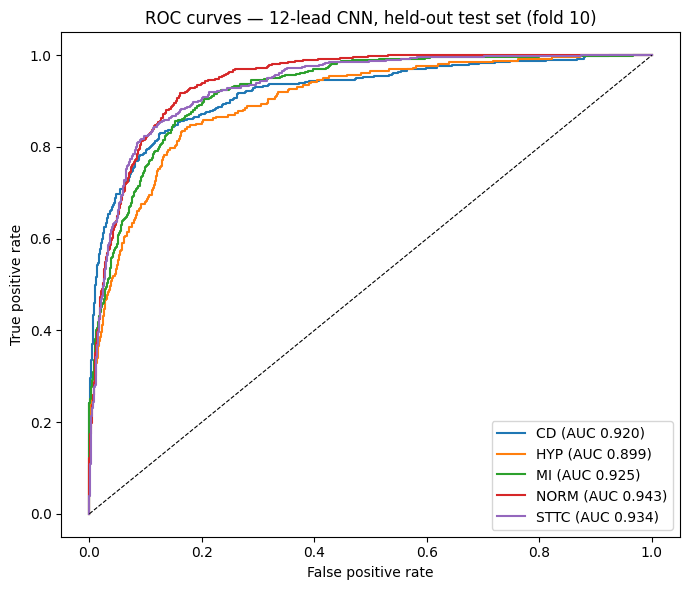

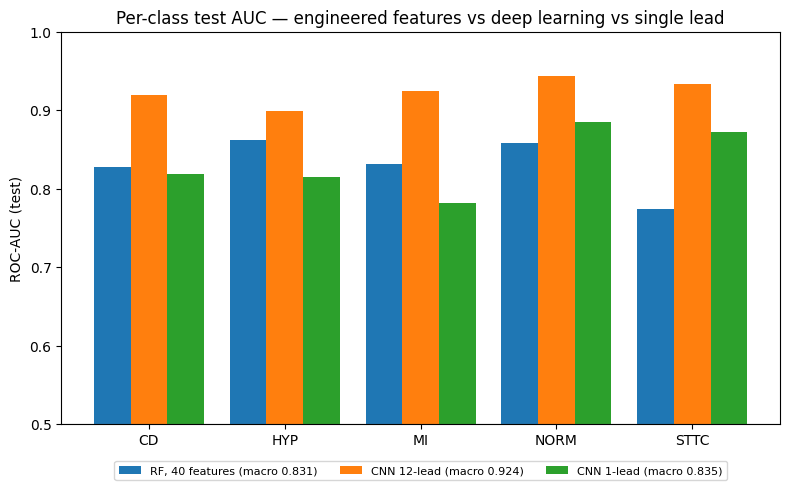

Figures saved to /content/drive/MyDrive/ptbxl/figures


In [18]:
from sklearn.metrics import roc_curve

fig_dir = f'{data_dir}/figures'
os.makedirs(fig_dir, exist_ok=True)

def get_probs(dl, net):
    """Return (y_true, y_proba) for a DataLoader and a trained network."""
    net.eval()
    ps, ys = [], []
    with torch.no_grad():
        for xb, yb in dl:
            ps.append(torch.sigmoid(net(xb.to(device))).cpu().numpy())
            ys.append(yb.numpy())
    return np.vstack(ys), np.vstack(ps)

# Rebuild both CNNs and load their best checkpoints
# (the `model` variable currently holds the 1-lead network after section 9)
cnn12 = nn.Sequential(
    conv_block(12, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, 5)).to(device)
cnn12.load_state_dict(torch.load(f'{data_dir}/cnn_best.pt'))

cnn1 = nn.Sequential(
    conv_block(1, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128),
    nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, 5)).to(device)
cnn1.load_state_dict(torch.load(f'{data_dir}/cnn_1lead_best.pt'))

y_true, p_cnn = get_probs(dl_te, cnn12)
_,      p_1l  = get_probs(dl_te1, cnn1)

# --- Figure 1: ROC curves per superclass (12-lead CNN, test set) ---
plt.figure(figsize=(7, 6))
for k, c in enumerate(Y_lab.columns):
    fpr, tpr, _ = roc_curve(y_true[:, k], p_cnn[:, k])
    plt.plot(fpr, tpr, label=f'{c} (AUC {auc_cnn[k]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves — 12-lead CNN, held-out test set (fold 10)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{fig_dir}/roc_curves_test.png', dpi=150)
plt.show()

# --- Figure 2: per-class AUC, three models ---
x = np.arange(len(Y_lab.columns)); w = 0.27
plt.figure(figsize=(8, 5))
plt.bar(x - w, auc_rf_te, w, label=f'RF, 40 features (macro {auc_rf_te.mean():.3f})')
plt.bar(x,     auc_cnn,  w, label=f'CNN 12-lead (macro {auc_cnn.mean():.3f})')
plt.bar(x + w, auc_1l,   w, label=f'CNN 1-lead (macro {auc_1l.mean():.3f})')
plt.xticks(x, Y_lab.columns); plt.ylabel('ROC-AUC (test)')
plt.ylim(0.5, 1.0); plt.axhline(0.5, color='gray', linewidth=0.8)
plt.title('Per-class test AUC — engineered features vs deep learning vs single lead')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(f'{fig_dir}/auc_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

print('Figures saved to', fig_dir)

## 11. Conclusions and limitations

**What was shown, with own experiments:** (1) engineered features reach exactly as far as the knowledge encoded in them (HYP good, STTC poor); (2) a compact 1D CNN (~200k parameters) closes that gap and matches published benchmarks (test macro-AUC 0.924 vs ≈0.92–0.93); (3) the single-lead ceiling (0.835 macro, MI −0.143) is set by electrode geometry, not by the model.

**Limitations:** annotations are cardiologist statements, not ground truth from angiography/imaging; superclass aggregation hides within-class heterogeneity; no external dataset validation (single source); v1 feature set deliberately simple (no QRS delineation/HRV frequency features); no hyperparameter search, single architecture, single seed; class imbalance (HYP) handled only implicitly; decision thresholds not calibrated — outputs are rankings (AUC), not operating points.

**Extensions:** wavelet/delineation features for Phase A; deeper residual architectures and augmentation for Phase B; per-class threshold calibration; external validation (e.g. Chapman-Shaoxing); interpretability via saliency maps — *which* samples of the waveform drive each diagnosis.

---
*Author: Harjold Brahimaj — Biomedical Engineer. Educational project; not for clinical use.*